In [1]:
import pandas as pd
import numpy as np
from Bio import pairwise2
from Bio.pairwise2 import format_alignment
import time

/opt/homebrew/Caskroom/miniforge/base/envs/scanpy/lib/python3.10/site-packages/Bio/pairwise2.py:278: BiopythonDeprecationWarning: Bio.pairwise2 has been deprecated, and we intend to remove it in a future release of Biopython. As an alternative, please consider using Bio.Align.PairwiseAligner as a replacement, and contact the Biopython developers if you still need the Bio.pairwise2 module.
  warnings.warn(


In [2]:
def reverse(seq):
    complement = {'A': 'T', 'C': 'G', 'G': 'C', 'T': 'A'}
    reverse_complement = "".join(complement.get(base, base) for base in reversed(seq))
    return(reverse_complement)

print(reverse("ATGC"))

GCAT


In [3]:
probe_data = pd.read_excel('Cp_probes_old_genome_names_and_sequence.xlsx',header=None)
probe_data = probe_data.iloc[:-2]
#print(probe_data)
gff_data = []
with open('Genome_CLOSED/iAB4580001.gff') as file:
    for line in file.readlines():
        data = line.rstrip().split("\t")
        if line[0] in ['1','2','3','4','5','6']:
            gff_data.append(data)
file.close()
gff_data = pd.DataFrame(gff_data)

contigs = []
with open('Genome_CLOSED/iAB4580001.gff') as file:
    for l,line in enumerate(file.readlines()):
        if line[0] != ">":
            pass
        else:
            contig = []
            with open('Genome_CLOSED/iAB4580001.gff') as data:                
                for row in data.readlines()[l+1:]:
                    if row[0] == ">":
                        contigs.append("".join(contig))
                        break
                    else:
                        contig.append(row.rstrip())        
contigs.append("".join(contig))
data.close()
file.close()

for c,contig in enumerate(contigs):
    print(c,len(contig))

0 3378401
1 82478
2 69021
3 4125
4 3845
5 3200


In [4]:
print(len(gff_data))
print(gff_data)
count=0
for row in gff_data.iterrows():
    if 'hypothetical protein' in row[1][8]:
        count+=1
print(count)



3357
      0                1    2     3     4  5  6  7  \
0     1  Prodigal:002006  CDS     1  1374  .  +  0   
1     1  Prodigal:002006  CDS  1669  2769  .  +  0   
2     1  Prodigal:002006  CDS  2896  3102  .  +  0   
3     1  Prodigal:002006  CDS  3158  4243  .  +  0   
4     1  Prodigal:002006  CDS  4224  4517  .  +  0   
...  ..              ...  ...   ...   ... .. .. ..   
3352  5  Prodigal:002006  CDS   901  1422  .  +  0   
3353  5  Prodigal:002006  CDS  2147  3214  .  +  0   
3354  5  Prodigal:002006  CDS  3266  3730  .  -  0   
3355  6  Prodigal:002006  CDS   247  1284  .  -  0   
3356  6  Prodigal:002006  CDS  1902  2426  .  -  0   

                                                      8  
0     ID=NEKPDOIF_00001;Name=dnaA_1;db_xref=COG:COG0...  
1     ID=NEKPDOIF_00002;Name=dnaN;db_xref=COG:COG059...  
2     ID=NEKPDOIF_00003;inference=ab initio predicti...  
3     ID=NEKPDOIF_00004;Name=recF;db_xref=COG:COG119...  
4     ID=NEKPDOIF_00005;inference=ab initio predicti... 

In [5]:
probe_targets = list(set(["_".join(x.split("_")[0:2])+"_1" for x in probe_data.loc[:,0]]))
print(len(probe_targets))

probe_data_collapsed=probe_data[probe_data[0].isin(probe_targets)]
print(len(probe_targets))
print(len(probe_data_collapsed))

3189
3189
3189


In [7]:
mapped_data  = pd.read_excel('probe_gene_map.xlsx')

In [8]:
genes=[]
listt = [str(x).split(";") for x in mapped_data['Gene Description'].tolist()]
for x in listt:
    try:
        name = x[2]
        #print(name)
        if "Name=" in name:
            y = name[name.find("=")+1:name.find("_")]
            genes.append(y)
    except:
        pass
    #break

In [9]:
print(len(set(genes)))

501


In [10]:
df = pd.DataFrame(set(genes))

In [11]:
df.to_excel("genes.xlsx")

In [12]:
#################################################

In [74]:
gff_data = []
with open('Genome_CLOSED/iAB4580001.gff') as file:
    for line in file.readlines():
        data = line.rstrip().split("\t")
        if line[0] in ['1','2','3','4','5','6']:
            gff_data.append(data)
file.close()
gff_data = pd.DataFrame(gff_data)

gene_map = pd.read_excel("probe_gene_map.xlsx")

dge_df = pd.read_csv("ALL_1vsAll_Clusters_For_GSEA.csv")
cluster_genes=[dge_df['0_n'].tolist(), dge_df['1_n'].tolist(), dge_df['2_n'].tolist(), dge_df['3_n'].tolist(), dge_df['4_n'].tolist(), dge_df['5_n'].tolist(), dge_df['6_n'].tolist(), dge_df['7_n'].tolist()]




In [75]:
pd.DataFrame(cluster_genes)

,0,1,2,3,4,5,6,7,8,9,...,3106,3107,3108,3109,3110,3111,3112,3113,3114,3115
0,AD4700001_02203,AD4700001_02240,AD4700001_02322,AD4700001_02231,AD4700001_00117,AD4700001_02228,AD4700001_01819,AD4700001_01743,AD4700001_02227,AD4700001_02199,...,AD4700001_02239,AD4700001_02823,AD4700001_01123,AD4700001_02234,AD4700001_00070,AD4700001_00520,AD4700001_00723,AD4700001_01079,AD4700001_02200,AD4700001_01310
1,AD4700001_03283,AD4700001_01256,AD4700001_02234,AD4700001_02200,AD4700001_02239,AD4700001_02730,AD4700001_00555,AD4700001_02242,AD4700001_02201,AD4700001_01639,...,AD4700001_00117,AD4700001_01269,AD4700001_00974,AD4700001_02435,AD4700001_02199,AD4700001_02325,AD4700001_02322,AD4700001_02240,AD4700001_02815,AD4700001_02203
2,AD4700001_02200,AD4700001_01079,AD4700001_00217,AD4700001_01310,AD4700001_02823,AD4700001_00723,AD4700001_01649,AD4700001_01161,AD4700001_01698,AD4700001_02354,...,AD4700001_02228,AD4700001_01743,AD4700001_02231,AD4700001_00830,AD4700001_02203,AD4700001_02229,AD4700001_03283,AD4700001_01256,AD4700001_02218,AD4700001_01639
3,AD4700001_01079,AD4700001_02645,AD4700001_01080,AD4700001_00070,AD4700001_01077,AD4700001_02059,AD4700001_01649,AD4700001_01310,AD4700001_01078,AD4700001_03283,...,AD4700001_01743,AD4700001_01230,AD4700001_02227,AD4700001_02322,AD4700001_02237,AD4700001_02199,AD4700001_02203,AD4700001_02240,AD4700001_00830,AD4700001_02232
4,AD4700001_01310,AD4700001_00520,AD4700001_00723,AD4700001_02036,AD4700001_01742,AD4700001_02859,AD4700001_01123,AD4700001_01005,AD4700001_02823,AD4700001_00110,...,AD4700001_02228,AD4700001_02214,AD4700001_01743,AD4700001_02231,AD4700001_02229,AD4700001_02203,AD4700001_01639,AD4700001_02815,AD4700001_00830,AD4700001_03283
5,AD4700001_03283,AD4700001_03248,AD4700001_03247,AD4700001_03245,AD4700001_03136,AD4700001_03142,AD4700001_03249,AD4700001_02815,AD4700001_03246,AD4700001_03231,...,AD4700001_02223,AD4700001_02322,AD4700001_02224,AD4700001_02240,AD4700001_02203,AD4700001_02229,AD4700001_02226,AD4700001_02231,AD4700001_02228,AD4700001_02218
6,AD4700001_02234,AD4700001_01649,AD4700001_00682,AD4700001_01579,AD4700001_00575,AD4700001_02932,AD4700001_02397,AD4700001_01684,AD4700001_00461,AD4700001_02423,...,AD4700001_01674,AD4700001_01677,AD4700001_01819,AD4700001_02047,AD4700001_02259,AD4700001_02352,AD4700001_02815,AD4700001_02051,AD4700001_03283,AD4700001_02730
7,AD4700001_03248,AD4700001_03245,AD4700001_03249,AD4700001_03247,AD4700001_03246,AD4700001_02203,AD4700001_01743,AD4700001_02815,AD4700001_03022,AD4700001_00830,...,AD4700001_02730,AD4700001_00723,AD4700001_01999,AD4700001_02045,AD4700001_02352,AD4700001_02259,AD4700001_00555,AD4700001_01079,AD4700001_02200,AD4700001_01310


In [76]:
gene_map

,Unnamed: 0,Probe Index,Probe ID,Probe Seq,Probe Description,Gene Index,Gene ID,Gene Seq,Gene Type,Strand,Gene Description,Alignment Score
0,0,0,AD4700001_03244,tactcactatcttcaaggtagatatgtagttcctggaatgtgggga...,AD4700001 03244 K01387 CPE0173 cpe microbial c...,206,ID=NEKPDOIF_00207,ATGAAGAAAAACTTAAAAAGGGGAGAGCTAACAAAACTGAAGTTAG...,CDS,+,ID=NEKPDOIF_00207;eC_number=3.4.24.3;Name=colA...,100
1,1,1,AD4700001_03243,acttatgtgtttaccaatttgaaaactcaggtactggaaattacac...,AD4700001 03243 K01387 CPE0173 cpe microbial c...,207,ID=NEKPDOIF_00208,ATGTTAGTTAAGGGTACTTTATCAGAAGAGGATTATTCAGATAAAT...,CDS,+,ID=NEKPDOIF_00208;eC_number=3.4.24.3;Name=colA...,100
2,2,2,AD4700001_03234,tactaaccccatcctctggtcaggtgttagtaaatggacgagttcc...,AD4700001 03234 K01990 CPE0182 cpe ABC 2 type ...,217,ID=NEKPDOIF_00218,TTGATAAAAGTTGAAAATTTAACTAAGGAATTTAAAATTCGTAAAA...,CDS,-,ID=NEKPDOIF_00218;eC_number=7.6.2.8;Name=btuD_...,100
3,3,3,AD4700001_03290,ataaatggtatgaataatataacattccatgttgaaatttcagaag...,AD4700001 03290 hypothetical protein3,1179,ID=NEKPDOIF_01180,ATGAAAAAATTGGAATACAACCCATATTTAATAGATAAAATTCAAC...,CDS,+,ID=NEKPDOIF_01180;inference=ab initio predicti...,100
4,4,4,AD4700001_02269,tggtgatggaccattttcgccagaaagagcaggtggagttccttca...,AD4700001 02269 K00929 CPE2347 cpe butyrate ki...,2830,ID=NEKPDOIF_02831,ATGGCATATAAATTATTAATAATAAATCCAGGGTCTACATCAACTA...,CDS,-,ID=NEKPDOIF_02831;eC_number=2.7.2.7;Name=buk2;...,100
...,...,...,...,...,...,...,...,...,...,...,...,...
3092,3092,3184,AD4700001_02274,caaacccaattccatggttaacagatccaacatgggcaagggtagc...,AD4700001 02274 K15771 CPE2342 cpe arabinogala...,2825,ID=NEKPDOIF_02826,ATGCAAGTTACGAGTGATAGAAGGGCAGATAAAAAGCAGAAAAGGT...,CDS,-,ID=NEKPDOIF_02826;Name=malF;db_xref=COG:COG117...,100
3093,3093,3185,AD4700001_02273,ccaatgcctaacataccagaaattcaagctatgtggggacctgctg...,AD4700001 02273 K15770 CPE2343 cpe arabinogala...,2826,ID=NEKPDOIF_02827,ATGGGAAAACGTACAAAAATTCTAGCGACTGTAATGGCTGCAACAA...,CDS,-,ID=NEKPDOIF_02827;Name=cycB;db_xref=COG:COG218...,100
3094,3094,3186,AD4700001_02272,tgtactatcagattttgataattgtgataaggtttctttagaattc...,AD4700001 02272 K02647 Tsac 1236 tsh carbohydr...,2827,ID=NEKPDOIF_02828,ATGTACAGTTTTCATAAGTTCTTAGAAGAGTTATATTTAAATACTA...,CDS,-,ID=NEKPDOIF_02828;inference=ab initio predicti...,100
3095,3095,3187,AD4700001_02271,atagcgatggttttccaaagttacgcactatatccacatatgactg...,AD4700001 02271 K10112 CPE2345 cpe multiple su...,2828,ID=NEKPDOIF_02829,ATGGCAAATTTATCACTTAAACATATTTATAAAGTTTATCCAGGAG...,CDS,-,ID=NEKPDOIF_02829;eC_number=7.5.2.-;Name=msmX;...,100


In [77]:
gff_data

,0,1,2,3,4,5,6,7,8
0,1,Prodigal:002006,CDS,1,1374,.,+,0,ID=NEKPDOIF_00001;Name=dnaA_1;db_xref=COG:COG0...
1,1,Prodigal:002006,CDS,1669,2769,.,+,0,ID=NEKPDOIF_00002;Name=dnaN;db_xref=COG:COG059...
2,1,Prodigal:002006,CDS,2896,3102,.,+,0,ID=NEKPDOIF_00003;inference=ab initio predicti...
3,1,Prodigal:002006,CDS,3158,4243,.,+,0,ID=NEKPDOIF_00004;Name=recF;db_xref=COG:COG119...
4,1,Prodigal:002006,CDS,4224,4517,.,+,0,ID=NEKPDOIF_00005;inference=ab initio predicti...
...,...,...,...,...,...,...,...,...,...
3352,5,Prodigal:002006,CDS,901,1422,.,+,0,ID=NEKPDOIF_03353;inference=ab initio predicti...
3353,5,Prodigal:002006,CDS,2147,3214,.,+,0,ID=NEKPDOIF_03354;inference=ab initio predicti...
3354,5,Prodigal:002006,CDS,3266,3730,.,-,0,ID=NEKPDOIF_03355;inference=ab initio predicti...
3355,6,Prodigal:002006,CDS,247,1284,.,-,0,ID=NEKPDOIF_03356;inference=ab initio predicti...


In [78]:
# this step takes a long time!

matches = []
for c,cluster in enumerate(cluster_genes):
    print(c)
    for g,gene in enumerate(cluster):
        print(gene)
        for row in gene_map.iterrows():
            if gene == row[1]["Probe ID"]:
                description = row[1]["Gene Description"]
                description_2 = row[1]["Probe Description"]
                print('yes')
                for line in gff_data.iterrows():
                    if line[1][8]==description:
                        print('good')
                        contig = line[1][0]
                        tyype = line[1][2]  
                        matches.append([c,gene,contig,tyype,description,description_2])
                        print("Found")
                        break
                
                break

0
AD4700001_02203
yes
good
Found
AD4700001_02240
yes
good
Found
AD4700001_02322
yes
good
Found
AD4700001_02231
yes
good
Found
AD4700001_00117
yes
good
Found
AD4700001_02228
yes
good
Found
AD4700001_01819
yes
good
Found
AD4700001_01743
yes
good
Found
AD4700001_02227
yes
good
Found
AD4700001_02199
yes
good
Found
AD4700001_00830
yes
good
Found
AD4700001_02238
yes
good
Found
AD4700001_02325
yes
good
Found
AD4700001_00275
AD4700001_02213
yes
good
Found
AD4700001_02232
yes
good
Found
AD4700001_02323
yes
good
Found
AD4700001_02229
yes
good
Found
AD4700001_01758
yes
good
Found
AD4700001_00274
yes
good
Found
AD4700001_02224
yes
good
Found
AD4700001_02226
yes
good
Found
AD4700001_01396
yes
good
Found
AD4700001_01232
yes
good
Found
AD4700001_00646
yes
good
Found
AD4700001_02223
yes
good
Found
AD4700001_01254
yes
good
Found
AD4700001_02051
yes
good
Found
AD4700001_01658
yes
good
Found
AD4700001_02413
yes
good
Found
AD4700001_02214
yes
good
Found
AD4700001_01269
yes
good
Found
AD4700001_02209
yes
g

In [79]:
matches

[[0,
  'AD4700001_02203',
  '1',
  'CDS',
  'ID=NEKPDOIF_02897;Name=rplL;gene=rplL;inference=ab initio prediction:Prodigal:002006,similar to AA sequence:UniProtKB:P02395;locus_tag=NEKPDOIF_02897;product=50S ribosomal protein L7/L12',
  'AD4700001 02203 K02935 Gferi 17335 gfe large subunit ribosomal protein L7 L121'],
 [0,
  'AD4700001_02240',
  '1',
  'CDS',
  'ID=NEKPDOIF_02860;Name=rpsD_2;db_xref=COG:COG0522;gene=rpsD_2;inference=ab initio prediction:Prodigal:002006,similar to AA sequence:UniProtKB:P80373;locus_tag=NEKPDOIF_02860;product=30S ribosomal protein S4',
  'AD4700001 02240 K02986 Cbei 0179 cbe small subunit ribosomal protein S41'],
 [0,
  'AD4700001_02322',
  '1',
  'CDS',
  'ID=NEKPDOIF_02775;eC_number=4.2.1.150;Name=crt;db_xref=COG:COG1024;gene=crt;inference=ab initio prediction:Prodigal:002006,similar to AA sequence:UniProtKB:P52046;locus_tag=NEKPDOIF_02775;product=Short-chain-enoyl-CoA hydratase',
  'AD4700001 02322 K01715 CPE2301 cpe enoyl CoA hydratase  EC 4.2.1.17 1'

In [82]:
match_df = pd.DataFrame(matches,columns=["Cluster","Probe","Contig","Gene Type","PGAP Annotation","Original Annotation"])

In [83]:
match_df.to_excel("DGE_analysis_ALL_1vsAll.xlsx")

In [84]:
import json

In [85]:
#KEGG_dict = json.loads("KEGG_modules.json")

f = open('KEGG_modules.json','r')
   
# returns JSON object as 
# a dictionary
data = json.load(f)
f.close()

module_data =[]
for i in data['children']:
    for x in i['children']:
        print(x['name'])
        for y in x['children']:
            #print(y['name'])
            module = y['name']
            genes = []
            try:
                for q in y['children']:
                    z = q['name'].split(" ")[0]
                    #if "[EC:" in z:
                    #    #print(z)
                    #    pool.append(z[z.find("[EC:"):])
                
                #genes = []
                #for entry in pool:
                #    val = entry.split(" ")
                #    for v in val:
                #        for char in ["[","]","EC:"]:
                #            v = v.replace(char,"")
                #        genes.append(v)
                    genes.append(z)
                module_data.append([module,list(set(genes))])
            except KeyError:
                pass

print(len(module_data))
KEGG_modules = [x for x in module_data if len(x[1])>0]
print(len(KEGG_modules))

09101 Carbohydrate metabolism
09102 Energy metabolism
09103 Lipid metabolism
09104 Nucleotide metabolism
09105 Amino acid metabolism
09106 Metabolism of other amino acids
09107 Glycan biosynthesis and metabolism
09108 Metabolism of cofactors and vitamins
09109 Metabolism of terpenoids and polyketides
09110 Biosynthesis of other secondary metabolites
09111 Xenobiotics biodegradation and metabolism
09112 Not included in regular maps
09121 Transcription
09122 Translation
09123 Folding, sorting and degradation
09124 Replication and repair
09125 Information processing in viruses
09131 Membrane transport
09132 Signal transduction
09133 Signaling molecules and interaction
09141 Transport and catabolism
09143 Cell growth and death
09144 Cellular community - eukaryotes
09145 Cellular community - prokaryotes
09142 Cell motility
09151 Immune system
09152 Endocrine system
09153 Circulatory system
09154 Digestive system
09155 Excretory system
09156 Nervous system
09157 Sensory system
09158 Developm

In [86]:
for x in KEGG_modules:
    print(x[0],len(x[1]))

00010 Glycolysis / Gluconeogenesis [PATH:ko00010] 107
00020 Citrate cycle (TCA cycle) [PATH:ko00020] 63
00030 Pentose phosphate pathway [PATH:ko00030] 85
00040 Pentose and glucuronate interconversions [PATH:ko00040] 85
00051 Fructose and mannose metabolism [PATH:ko00051] 111
00052 Galactose metabolism [PATH:ko00052] 78
00053 Ascorbate and aldarate metabolism [PATH:ko00053] 62
00500 Starch and sucrose metabolism [PATH:ko00500] 106
00520 Amino sugar and nucleotide sugar metabolism [PATH:ko00520] 156
00620 Pyruvate metabolism [PATH:ko00620] 127
00630 Glyoxylate and dicarboxylate metabolism [PATH:ko00630] 101
00640 Propanoate metabolism [PATH:ko00640] 96
00650 Butanoate metabolism [PATH:ko00650] 110
00660 C5-Branched dibasic acid metabolism [PATH:ko00660] 29
00562 Inositol phosphate metabolism [PATH:ko00562] 76
00190 Oxidative phosphorylation [PATH:ko00190] 219
00195 Photosynthesis [PATH:ko00195] 63
00196 Photosynthesis - antenna proteins [PATH:ko00196] 42
00710 Carbon fixation in photosyn

In [89]:
DGE_df = pd.read_excel("DGE_analysis_ALL_1vsAll.xlsx")

for r,row in enumerate(DGE_df.iterrows()):
    x = row[1]["Original Annotation"].split(" ")
    if "K" in x[2]:
        KO = x[2]
    else:
        KO = None
    print(r,row[1]["Cluster"],KO)
    for module in KEGG_modules:
        if KO in module[1]:
            print(module[0])

0 0 K02935
03010 Ribosome [PATH:ko03010]
03011 Ribosome [BR:ko03011]
1 0 K02986
03010 Ribosome [PATH:ko03010]
03011 Ribosome [BR:ko03011]
2 0 K01715
00650 Butanoate metabolism [PATH:ko00650]
3 0 K02876
03010 Ribosome [PATH:ko03010]
03011 Ribosome [BR:ko03011]
4 0 K19824
99982 Energy metabolism
5 0 K02881
03010 Ribosome [PATH:ko03010]
03011 Ribosome [BR:ko03011]
6 0 K00626
00620 Pyruvate metabolism [PATH:ko00620]
00630 Glyoxylate and dicarboxylate metabolism [PATH:ko00630]
00650 Butanoate metabolism [PATH:ko00650]
00720 Carbon fixation pathways in prokaryotes [PATH:ko00720]
00071 Fatty acid degradation [PATH:ko00071]
00280 Valine, leucine and isoleucine degradation [PATH:ko00280]
00310 Lysine degradation [PATH:ko00310]
00380 Tryptophan metabolism [PATH:ko00380]
00900 Terpenoid backbone biosynthesis [PATH:ko00900]
00362 Benzoate degradation [PATH:ko00362]
02020 Two-component system [PATH:ko02020]
04975 Fat digestion and absorption [PATH:ko04975]
04147 Exosome [BR:ko04147]
7 0 K02899
0301

In [90]:
probe_gene_map = pd.read_excel("probe_gene_map.xlsx")

KOs = []
for row in probe_gene_map.iterrows():
    x = row[1]["Probe Description"].split(" ")
    
    if "K" in x[2]:
        KO = x[2]
        KOs.append(KO)
    else:
        pass
        
    
print(len(KOs))
print(len(set(KOs)))
KOs = set(KOs)

print(KOs)

2086
1423
{'K13542', 'K17103', 'K02619', 'K02874', 'K03303', 'K07726', 'K13283', 'K13038', 'K10440', 'K11630', 'K00625', 'K10027', 'K09812', 'K00626', 'K00845', 'K02878', 'K14983', 'K00925', 'K01056', 'K16963', 'K06398', 'K02226', 'K10844', 'K06379', 'K18346', 'K03575', 'K02015', 'K00609', 'K07282', 'K06412', 'K11057', 'K01874', 'K01042', 'K00963', 'K06958', 'K08986', 'K21064', 'K00336', 'K02956', 'K06193', 'K03735', 'K12410', 'K02009', 'K02116', 'K10439', 'K02881', 'K01173', 'K09762', 'K03802', 'K02760', 'K02123', 'K03639', 'K02994', 'K01091', 'K00797', 'K00949', 'K07455', 'K01462', 'K02886', 'K02803', 'K06393', 'K01485', 'K03092', 'K01495', 'K10231', 'K03431', 'K07816', 'K01478', 'K18640', 'K03555', 'K07037', 'K01424', 'K07452', 'K20965', 'K16326', 'K03711', 'K10947', 'K00939', 'K01686', 'K08302', 'K02970', 'K00694', 'K15738', 'K02049', 'K01740', 'K02888', 'K00783', 'K21449', 'K00965', 'K02834', 'K02669', 'K09825', 'K01876', 'K01520', 'K01304', 'K09903', 'K02961', 'K00554', 'K01869',

In [93]:
valid_modules = []
for KO in KOs:
    for module in KEGG_modules:
        if KO in module[1] and module[0] not in [x[0] for x in valid_modules]:
            valid_modules.append(module)
            

In [94]:
print(len(KEGG_modules))
print(len(valid_modules))

534
274


In [95]:
for x in valid_modules:
    print(x[0],len(x[1]))

00860 Porphyrin metabolism [PATH:ko00860] 139
00564 Glycerophospholipid metabolism [PATH:ko00564] 115
00260 Glycine, serine and threonine metabolism [PATH:ko00260] 103
00790 Folate biosynthesis [PATH:ko00790] 84
03010 Ribosome [PATH:ko03010] 143
03011 Ribosome [BR:ko03011] 188
02000 Transporters [BR:ko02000] 1917
03000 Transcription factors [BR:ko03000] 1365
00770 Pantothenate and CoA biosynthesis [PATH:ko00770] 44
02010 ABC transporters [PATH:ko02010] 514
02020 Two-component system [PATH:ko02020] 498
02022 Two-component system [BR:ko02022] 263
00620 Pyruvate metabolism [PATH:ko00620] 127
00640 Propanoate metabolism [PATH:ko00640] 96
00720 Carbon fixation pathways in prokaryotes [PATH:ko00720] 112
00680 Methane metabolism [PATH:ko00680] 195
00430 Taurine and hypotaurine metabolism [PATH:ko00430] 26
00906 Carotenoid biosynthesis [PATH:ko00906] 56
03036 Chromosome and associated proteins [BR:ko03036] 1213
00630 Glyoxylate and dicarboxylate metabolism [PATH:ko00630] 101
00650 Butanoate me

In [96]:
### compiling list of all unique KO terms within valid modules (i.e. modules containing a KO term found in C perfringen genome, 277 out of 534 total modules)

KO_list = []
for m in valid_modules:
    for x in m[1]:
        KO_list.append(x)
        
print(len(KO_list))
print(len(set(KO_list)))
KO_list = list(set(KO_list))

print(len(KOs)) # unique KO terms from annotated C perfringens genome

module_dict = {}
for m in valid_modules:
    tabs = []
    for x in m[1]:
        if x in KOs:
            tabs.append(x)
    print(m[0],len(m[1]),len(tabs))
    
    if len(tabs)>2:
        module_dict[m[0]]=tabs
    
print(len(module_dict))


count=0
for ko in KOs:
    if ko in KO_list:
        count+=1

print(len(KOs))
print(count) #1449 out of 1457 of unique KOs in C perfringen genome are included in KEGG modules, cool! 

37074
21487
1423
00860 Porphyrin metabolism [PATH:ko00860] 139 31
00564 Glycerophospholipid metabolism [PATH:ko00564] 115 18
00260 Glycine, serine and threonine metabolism [PATH:ko00260] 103 12
00790 Folate biosynthesis [PATH:ko00790] 84 18
03010 Ribosome [PATH:ko03010] 143 51
03011 Ribosome [BR:ko03011] 188 51
02000 Transporters [BR:ko02000] 1917 167
03000 Transcription factors [BR:ko03000] 1365 64
00770 Pantothenate and CoA biosynthesis [PATH:ko00770] 44 7
02010 ABC transporters [PATH:ko02010] 514 57
02020 Two-component system [PATH:ko02020] 498 44
02022 Two-component system [BR:ko02022] 263 29
00620 Pyruvate metabolism [PATH:ko00620] 127 24
00640 Propanoate metabolism [PATH:ko00640] 96 13
00720 Carbon fixation pathways in prokaryotes [PATH:ko00720] 112 14
00680 Methane metabolism [PATH:ko00680] 195 17
00430 Taurine and hypotaurine metabolism [PATH:ko00430] 26 4
00906 Carotenoid biosynthesis [PATH:ko00906] 56 1
03036 Chromosome and associated proteins [BR:ko03036] 1213 39
00630 Glyox

In [119]:
#module_list = []
#for m in module_dict:
#    #print(m)
#    #print(module_dict[m])
#    module_list.append([m,len(module_dict[m]),module_dict[m]])
    
#module_df = pd.DataFrame(module_list)
#module_df.to_excel("module_list.xlsx")

final_modules={}
final_module_list = pd.read_excel("final_module_list.xlsx",sheet_name="Sheet2")
print(len(final_module_list))
for row in final_module_list.iterrows():
    module_name = row[1][0]
    #print(module_name)
    genes = row[1][2]
    lst = []
    for x in genes.split(","):
        #x = x.replace("\'","")
        #x = x.replace("[","")
        #x = x.replace("]","")
        #print(x)
        term=""
        #print(x)
        for char in x:
            if char in ["K",'0','1','2','3','4','5','6','7','8','9']:
                term+=char
        lst.append(term)
    #print(module_name)
    #print(lst)
    final_modules[module_name]=lst

terms = []
for x in final_modules.keys():
    terms+=final_modules[x]

#print(len(terms))
#print(len(set(terms)))

count = len(set(terms))
print(count)

133
1197


In [120]:
DGE_df = pd.read_csv("ALL_1vsAll_Clusters_For_GSEA.csv")

cluster_genes=[]
#for x in ["0_n","1_n","2_n","3_n", "4_n", "5_n", "6_n", "7_n", "8_n", "9_n"]:
for x in ["0_n","1_n","2_n","3_n", "4_n", "5_n","6_n", "7_n"]:
    lstttt = []
    for gene in DGE_df[x].tolist():
        cell = DGE_df.loc[DGE_df[x]==gene]
        if cell[x.replace("_n","_p")].tolist()[0]<0.000001 and cell[x.replace("_n","_l")].tolist()[0]>0:
            #print(cell[x.replace("_names","_pvals")].tolist()[0])
            lstttt.append(gene)
    cluster_genes.append(lstttt)
        

gff_data = []
with open('Genome_CLOSED/iAB4580001.gff') as file:
    for line in file.readlines():
        data = line.rstrip().split("\t")
        if line[0] in ['1','2','3','4','5','6']:
            gff_data.append(data)
file.close()
gff_data = pd.DataFrame(gff_data)

gene_map = pd.read_excel("probe_gene_map.xlsx")

matches = []
for c,cluster in enumerate(cluster_genes):
    v = 0
    for g,gene in enumerate(cluster):
        #print(gene)
        for row in gene_map.iterrows():
            if gene == row[1]["Probe ID"]:
                description = row[1]["Gene Description"]
                description_2 = row[1]["Probe Description"]
                for line in gff_data.iterrows():
                    if line[1][8]==description:
                        v+=1
                        contig = line[1][0]
                        tyype = line[1][2]
                        matches.append([c,gene,contig,tyype,description,description_2])
                        #print("Found")
                        break
                
                break
    print(c,v)
                
match_df = pd.DataFrame(matches,columns=["Cluster","Probe","Contig","Gene Type","PGAP Annotation","Original Annotation"])

match_df.to_excel("ALL_1vsAll_Clusters_After_GSEA.xlsx")


0 345
1 89
2 20
3 35
4 23
5 11
6 17
7 25


In [121]:
from scipy import stats
import matplotlib.pyplot as plt


In [124]:
# here every cluster is tested individually by changing cluster = 

match_df = pd.read_excel("ALL_1vsAll_Clusters_After_GSEA.xlsx")
print(len(match_df))
match_df = match_df[~match_df["Original Annotation"].str.contains("hypothetical")]
print(len(match_df))

cluster_dict = {}
for x in final_modules.keys():
    cluster_dict[x]=[]
    
cluster = 0 # change cluster here 
cluster_genes = match_df.loc[(match_df['Cluster']==cluster)]

if len(cluster_genes)>500:
    cluster_genes = cluster_genes.head(50)
    
print(len(cluster_genes))

tracker=0
for i,row in enumerate(cluster_genes.iterrows()):
    x = row[1]["Original Annotation"].split(" ")
    if "K" in x[2]:
        KO = x[2]
        for key in final_modules.keys():
            if KO in final_modules[key]:
                cluster_dict[key].append(KO)
        tracker+=1

565
520
318


In [125]:
final_modules.keys()

dict_keys(['01504 Antimicrobial resistance genes [BR:ko01504]', '03018 RNA degradation [PATH:ko03018]', '03019 Messenger RNA biogenesis [BR:ko03019]', '03000 Transcription factors [BR:ko03000]', '03440 Homologous recombination [PATH:ko03440]', '03400 DNA repair and recombination proteins [BR:ko03400]', '03010 Ribosome [PATH:ko03010]', '00270 Cysteine and methionine metabolism [PATH:ko00270]', '00190 Oxidative phosphorylation [PATH:ko00190]', '03110 Chaperones and folding catalysts [BR:ko03110]', '02010 ABC transporters [PATH:ko02010]', '00010 Glycolysis / Gluconeogenesis [PATH:ko00010]', '00030 Pentose phosphate pathway [PATH:ko00030]', '00051 Fructose and mannose metabolism [PATH:ko00051]', '00052 Galactose metabolism [PATH:ko00052]', '00680 Methane metabolism [PATH:ko00680]', '04066 HIF-1 signaling pathway [PATH:ko04066]', '04922 Glucagon signaling pathway [PATH:ko04922]', '01009 Protein phosphatases and associated proteins [BR:ko01009]', '00230 Purine metabolism [PATH:ko00230]', '00

In [126]:
#import matplotlib
#print(matplotlib.__version__)

[0, '03010 Ribosome [PATH:ko03010]', 33, 309, 52, 1197, 2.5, 5.468535469107551, 9.312856041887585e-10, {'K02967', 'K02952', 'K02931', 'K02994', 'K02895', 'K02874', 'K02946', 'K02890', 'K02996', 'K02982', 'K02990', 'K02926', 'K02935', 'K02988', 'K02970', 'K02892', 'K02933', 'K02876', 'K02992', 'K02899', 'K02904', 'K02954', 'K02884', 'K02963', 'K02956', 'K02878', 'K02986', 'K02907', 'K02888', 'K02909', 'K02968', 'K02881', 'K02916'}]
[0, '00190 Oxidative phosphorylation [PATH:ko00190]', 15, 309, 20, 1197, 2.9, 9.010204081632653, 4.848208459140579e-07, {'K02122', 'K15986', 'K02112', 'K02111', 'K02110', 'K02115', 'K02118', 'K02109', 'K00336', 'K02121', 'K02120', 'K02124', 'K02117', 'K02119', 'K02113'}]
[0, '00061 Fatty acid biosynthesis [PATH:ko00061]', 10, 309, 12, 1197, 3.2, 14.816053511705686, 2.74041906478395e-06, {'K01961', 'K01962', 'K00059', 'K00209', 'K00645', 'K02160', 'K09458', 'K02372', 'K01963', 'K00648'}]
[[0, '03010 Ribosome [PATH:ko03010]', 33, 309, 51, 1197, 5.46853546910755

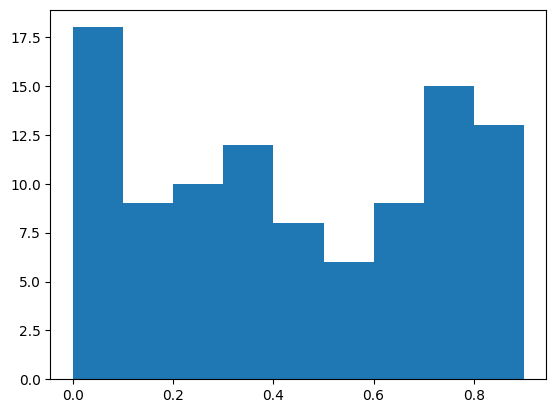

In [127]:
p_vals = []
h = []
for key in cluster_dict.keys():
    enrichment = round((len(cluster_dict[key])/tracker)/(len(final_modules[key])/count),1)
    #print(enrichment)
    
    x =len(set(cluster_dict[key])) #differentially expressed genes in GO term
    #print(x)
    k = tracker #differentially expressed genes
    #print(k)
    m = len(set(final_modules[key])) #genes in GO term
    #print(m)
    n = count - len(set(final_modules[key])) # genes not in GO term
    #print(n)
    f = stats.fisher_exact(table=[[x,m-x],[k-x,n-(k-x)]], alternative="less")
    #print(f[0],1-f[1])
    
    p_vals.append(f[1])
    
    if 1-f[1] < 0.05/len(cluster_dict) and x>1:
        h.append([cluster,key,len(cluster_dict[key]),tracker,len(module_dict[key]),count,f[0],1-f[1],set(cluster_dict[key])])
        print([cluster,key,len(cluster_dict[key]),tracker,len(final_modules[key]),count,enrichment,f[0],1-f[1],set(cluster_dict[key])])
print(h)

df_output = pd.DataFrame(h,columns=["Cluster","KEGG Module","Num. of DEG in Module","Num. of DEG in Cluster","# of genes in module","total # of genes considered","oddsratio","pval","implicated genes"])
df_output.to_excel("GSEA_cluster_"+str(cluster)+"_LC.xlsx")
        
plt.figure()
plt.hist(p_vals,bins=np.arange(0,1,0.1))
plt.show()